In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Kaggle dataset path not found. Switching to scikit-learn built-in Digits dataset for offline testing.
   label    0    1    2     3     4     5    6    7    8  ...   54   55   56  \
0      0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1      1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2      2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  ...  5.0  0.0  0.0   
3      3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  ...  9.0  0.0  0.0   
4      4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    57   58    59    60    61   62   63  
0  0.0  6.0  13.0  10.0   0.0  0.0  0.0  
1  0.0  0.0  11.0  16.0  10.0  0.0  0.0  
2  0.0  0.0   3.0  11.0  16.0  9.0  0.0  
3  0.0  7.0  13.0  13.0   9.0  0.0  0.0  
4  0.0  0.0   2.0  16.0   4.0  0.0  0.0  

[5 rows x 65 columns]
Dataset Shape: (1797, 65)


Choose Algorithm (1. Decision Tree, 2. SVM):  1


Labels shape (y): (1797,)
Features shape (X): (1797, 64)
Training data: (1437, 64)
Testing data: (360, 64)
Accuracy: 86.94%


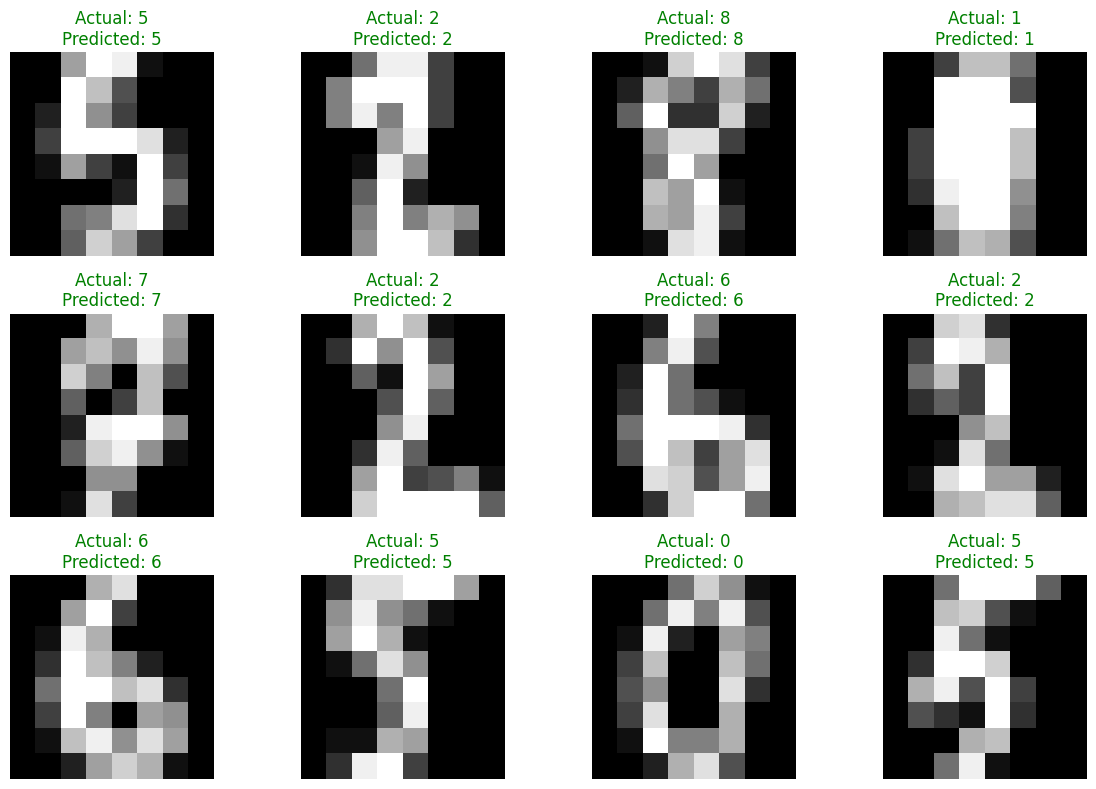

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Try loading the EMNIST file from Kaggle, otherwise fallback to scikit-learn digits dataset
filepath = '/kaggle/input/datasets/crawford/emnist/emnist-balanced-train.csv'

try:
  df = pd.read_csv(filepath)
  print('Successfully loaded EMNIST from Kaggle path!')
  is_emnist = True
except FileNotFoundError:
  print('Kaggle dataset path not found. Switching to scikit-learn built-in Digits dataset for offline testing.')
  digits = load_digits()
  # Build a DataFrame matching the structure: Column 0 = label, rest = 64 features
  df = pd.DataFrame(digits.data)
  df.insert(0, 'label', digits.target)
  is_emnist = False

print(df.head())
print('Dataset Shape:', df.shape)

algo = int(input('Choose Algorithm (1. Decision Tree, 2. SVM): '))

if algo == 1:
  # Decision Tree Block
  # Sample data if dataset is huge, otherwise use all rows
  sample_size = min(20000, len(df))
  df_sample = df.sample(n=sample_size, random_state=42)
  
  y = df_sample.iloc[:, 0]
  X = df_sample.iloc[:, 1:]

  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42, stratify=y
  )

  print('Labels shape (y):', y.shape)
  print('Features shape (X):', X.shape)
  print('Training data:', X_train.shape)
  print('Testing data:', X_test.shape)

  model = DecisionTreeClassifier(
      criterion='entropy', max_depth=10, random_state=42
  )
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)

  accuracy = accuracy_score(y_test, y_pred)
  print(f'Accuracy: {accuracy * 100:.2f}%')

  # Plotting 12 sample predictions
  plt.figure(figsize=(12, 8))
  img_shape = (28, 28) if is_emnist else (8, 8)
  
  for i in range(12):
    image = X_test.iloc[i].values.reshape(img_shape)
    if is_emnist:
      image = image.T  # Correct EMNIST orientation if needed

    plt.subplot(3, 4, i + 1)
    plt.imshow(image, cmap='gray')
    plt.title(
        f'Actual: {y_test.iloc[i]}\nPredicted: {y_pred[i]}',
        color='green' if y_test.iloc[i] == y_pred[i] else 'red',
    )
    plt.axis('off')

  plt.tight_layout()
  plt.show()

else:
  # SVM Block
  sample_size = min(20000, len(df))
  df_sample = df.sample(n=sample_size, random_state=42)
  
  y = df_sample.iloc[:, 0]
  X = df_sample.iloc[:, 1:]

  # Normalize pixel values to [0, 1]
  X = X / 16.0 if not is_emnist else X / 255.0

  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42, stratify=y
  )

  print('Labels shape (y):', y.shape)
  print('Features shape (X):', X.shape)
  print('Training Data:', X_train.shape)
  print('Testing Data:', X_test.shape)

  scaler = StandardScaler()
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled = scaler.transform(X_test)

  svm_model = SVC(kernel='linear', C=1.0, random_state=42)
  svm_model.fit(X_train_scaled, y_train)

  y_pred = svm_model.predict(X_test_scaled)

  print(f'Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.10f}%')
  print('\nClassification Report:\n', classification_report(y_test, y_pred))

  cm = confusion_matrix(y_test, y_pred)
  labels = np.unique(y)
  disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
  disp.plot(cmap='Reds', values_format='d')
  plt.title('Confusion Matrix')
  plt.show()